# Hybrid integrations with TRACE
REBOUND comes with several integrators, each of which has its own advantages and disadvantages. TRACE is a time-reversible hybrid integrator (Lu, Hernandez & Rein 2024) that is an improvement on the older MERCURIUS hybrid integrator. It uses a symplectic Wisdom-Holman integrator when particles are far apart from each other and switches over to a high order integrator during close encounters. Specifically, TRACE uses the efficient WHFast and Bulirsch-Stoer/IAS15 internally.

Let's start out by showcasing the problem with traditional fixed timestep integrators such as WHFast. We setup a simulation of the outer solar system and increase the masses of the planets by a factor of 50. 

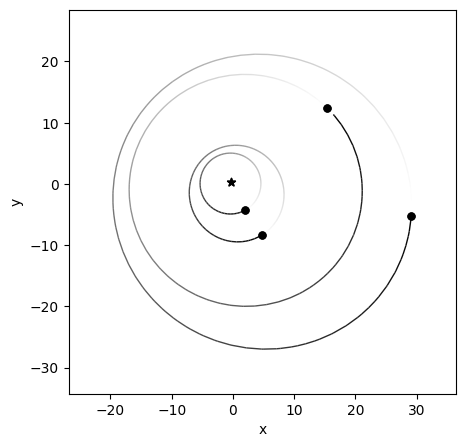

In [1]:
import math
import rebound
%matplotlib inline
sim = rebound.Simulation()
sim.add("outer solar system") # add some particles for testing
for i in range(1,sim.N):
    sim.particles[i].m *= 50.
sim.integrator = "WHFast" # This will end badly!
sim.dt = sim.particles[1].P * 0.002 # Timestep a small fraction of innermost planet's period
sim.move_to_com()
E0 = sim.energy() # Calculate initial energy 
rebound.OrbitPlot(sim);

Let us integrate this system for a few hundred years. An instability will occur. We can then measure the energy error, which is a good estimate as to how accurate the integration was.

In [2]:
sim.integrate(600*2.*math.pi)
E1 = sim.energy()
print("Relative energy error with WHFast: %f"%((E0-E1)/E0))

Relative energy error with WHFast: 6.366817


An energy error that large means we basically go it wrong completely. Let's try this again but use TRACE.

In [3]:
sim = rebound.Simulation()
sim.add("outer solar system") # add some particles for testing
for i in range(1,sim.N):
    sim.particles[i].m *= 50.
sim.integrator = "trace" 
sim.dt = sim.particles[1].P * 0.002 # Timestep a small fraction of innermost planet's period
sim.move_to_com()
E0 = sim.energy() # Calculate initial energy 
sim.integrate(600*2.*math.pi)
E1 = sim.energy()
print("Relative energy error with TRACE: %e"%((E1-E0)/E0))

Relative energy error with TRACE: -1.390839e-03


As you can see, TRACE is able to integrate this system with much better accuracy. When a close encounter occurs, it automatically (and reversibly!) switches to the BS integrator. When there is no close encounter, you still get all the benefits in terms of speed an accuracy from a symplectic integrator.

There are a few options to adjust TRACE. First of all, close encounters with the central star are treated differently than close encounters between planets. This becomes important in systems that deal with highly eccentric orbits. 

You can switch between two prescriptions that use the BS integrator:
* `PARTIAL_BS`, the fastest and least accurate method
* `FULL_BS`, which provides a good compromise between speed and accuracy (this is the default)

Or you may use the IAS15 integrator
* `FULL_IAS15`, which is the most accurate but slowest prescription (in most cases, this will have no significant accuracy advantage over `FULL_BS`)

See Lu, Hernandez & Rein (2024) for more details on these prescriptions.

In [4]:
# Sets the pericenter switching prescription
sim.integrator.peri_mode = "PARTIAL_BS" # or
sim.integrator.peri_mode = "FULL_BS"    # or
sim.integrator.peri_mode = "FULL_IAS15" # or

You also may want to change the criteria at which TRACE switches over from pure WHFast to BS/IAS15. For planet-planet encounters, this is expressed in units of a slightly modified Hill radii criteria. The default is 3 Hill radii, in the following we change it to 5 Hill radii (larger values result in more accurate but slower simulations):

In [5]:
sim.integrator.r_crit_hill = 5

For star-planet encounters, this is expressed as a parameter $\eta$, which is related to the ratio between the timestep and an adaptive timescale described in Dang, Rein & Spiegel (2024). The default is $\eta = 1$, we set it to $\eta = 0.1$ here (lower values result in more accurate but slower simulations):

In [6]:
sim.integrator.peri_crit_eta = 0.1